# Can Machine Learning Understand My Anime Taste?

CS156 - Pipeline Assignment 1

Can broad anime characteristics predict what becomes one of my favorites? I use my personal MyAnimeList archive to compare score prediction with a second, more practical question: can a model rank the titles I would give 10/10 above the rest? The goal is to measure whether the metadata add information beyond my strong tendency to assign high scores.

My ratings are preference tiers: 10 means a favorite, 9 means I liked it a lot, and 7-8 means it did not affect me as strongly. Very low scores can reflect strong dislike. These are ordered personal judgments, not calibrated measurements with equal psychological distances. I retain every valid low rating; deleting them as statistical outliers would erase meaningful preferences. The 1-6 band below is only an evaluation bucket, not a claim that every title in it is hated.

This notebook is the executable record. Run all cells from the repository root; all data are bundled. Model settings and the split are fixed in `src/pipeline.py`.

In [1]:
# Load local modules and record the exact data provenance and package version.
# No model is fitted in this setup cell; later cells control the split.
from pathlib import Path
import json, inspect, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
assert (ROOT / 'src/pipeline.py').exists(), 'Open this notebook from the project root.'
sys.path.insert(0, str(ROOT))
from src.ingest import parse_export
from src.pipeline import (load_data, preprocessing, regressors, run_experiments, FEATURES, TAGS)
import sklearn
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)
print('Metadata provenance:')
display(pd.Series(json.loads((ROOT/'data/provenance.json').read_text())))

Python: 3.13.15 | scikit-learn: 1.9.1
Metadata provenance:


source_url             https://github.com/manami-project/anime-offlin...
database_date                                                 2026-07-04
retrieved_date                                                2026-10-18
license                {'name': 'Open Data Commons Open Database Lice...
database_sha256        395be786fb2f98f1fca9e963911b9332110098a080e7e2...
original_xml_sha256    401bf57125c1c58f9e9059e84986ea671634f640eb80fe...
grouping               Undirected connected components over all full-...
dtype: object

## 1. Parse and audit the personal archive

The shared XML retains the original field structure needed for ingestion but omits the account header and unused tracking fields. The parser handles plain XML and gzip, checks unique IDs and validates scores. A 0 means unrated. Neither missing values nor very low ratings are silently discarded.

In [2]:
# Parse the shared raw XML and audit score/status frequencies before filtering.
# Score 0 remains visible here as an unrated marker. It is excluded from labels
# by the experiment function, and extreme valid personal scores are retained.
print(inspect.getsource(parse_export))
raw = pd.DataFrame(parse_export(ROOT/'data/animelist.xml'))
assert len(raw) == raw.anime_id.nunique() == 357
assert raw.score.between(0,10).all()
display(pd.crosstab(raw.status, raw.score))
print('All rated:', int((raw.score>0).sum()))
print('Unrated:', int((raw.score==0).sum()))
print('Share of rated entries scored 8-10:', raw.loc[raw.score>0,'score'].ge(8).mean())

def parse_export(path):
    """Read one XML export into a reproducibly ordered list of dictionaries.

    Args:
        path: Local plain XML file or a gzip-compressed file ending in .gz.

    Returns:
        Rows sorted by integer anime_id. Each row contains the title, exported
        type and episode count, personal score, and viewing status. Score 0 is
        preserved as the export's unrated marker; sample filtering happens in
        the modeling pipeline.

    Raises:
        ValueError: An integer field cannot be parsed, a score is outside 0-10,
            or the export contains duplicate anime IDs. XML parsing and file
            errors propagate so that a malformed archive cannot pass silently.
    """
    # ElementTree decodes the file's declared XML encoding from the byte stream.
    opener = gzip.open if Path(path).suffix == '.gz' else open
    with opener(path, 'rb') as stream:
        root = ET.parse(stream).getroot()
    rows = []
    for a in root.findall('anime'):

score,0,1,2,3,4,5,6,7,8,9,10
status,,,,,,,,,,,
Completed,5,7,7,3,5,4,20,21,67,65,95
Dropped,7,2,0,0,0,0,1,1,0,0,0
On-Hold,0,0,0,0,0,0,0,0,0,1,0
Plan to Watch,39,0,0,0,0,0,0,0,0,0,0
Watching,0,0,0,0,0,0,0,0,0,2,5


All rated: 306
Unrated: 51
Share of rated entries scored 8-10: 0.7679738562091504


## 2. Join metadata and define features

Jikan requests timed out, so this experiment uses the pinned manami-project 2026-27 release. All 357 MAL IDs match. The full ingestion code resolves relation edges over the entire metadata database before extracting this subset. Metadata date: July 4, 2026. The source is aggregated and non-curated; selected tags are broad genre/theme indicators, not a verified MAL genre taxonomy.

Primary population: completed and rated titles. Twelve other rated titles remain available for a development-only population sensitivity. Features exclude community ratings, title text, personal dates, progress, IDs and watch status. The original export supplies episode count, transformed with `log1p`; unknown counts would be imputed. All studios are retained, not just the first.

In [3]:
# Inspect deterministic feature preparation and the primary sample definition.
# Encoding vocabularies, medians, and scaling statistics are learned later
# inside training partitions. Relation-group counts expose dependent titles.
df = load_data()
primary = df[(df.score>0)&(df.status=='Completed')].copy()
assert len(primary)==294 and primary.matched.all()
print('Predeclared broad tag vocabulary:', sorted(TAGS))
display(primary[['title','score','tags','studios','type','year','log_episodes']].head())
display(primary[['year','log_episodes']].isna().sum())
print('Relation components:', primary.relation_group.nunique())
print('Largest components:')
display(primary.groupby('relation_group').size().sort_values(ascending=False).head(10))
print(inspect.getsource(preprocessing))

Predeclared broad tag vocabulary: ['action', 'adventure', 'comedy', 'detective', 'detectives', 'drama', 'ecchi', 'fantasy', 'gore', 'harem', 'historical', 'horror', 'isekai', 'iyashikei', 'josei', 'martial arts', 'mecha', 'military', 'music', 'mystery', 'parody', 'psychological', 'romance', 'samurai', 'school', 'school life', 'sci-fi', 'science fiction', 'seinen', 'shoujo', 'shounen', 'slice of life', 'space', 'sports', 'super power', 'supernatural', 'survival', 'suspense', 'thriller', 'time travel', 'vampire', 'vampires', 'workplace']


,title,score,tags,studios,type,year,log_episodes
1,Monster,10,detective|drama|gore|historical|horror|mystery...,madhouse inc.,TV,2004,4.317488
2,Naruto,8,action|adventure|comedy|drama|fantasy|martial ...,"pierrot co., ltd.",TV,2002,5.398163
4,Shinseiki Evangelion,10,action|comedy|drama|gore|mecha|military|myster...,"gainax co., ltd.|tatsunoko production co., ltd.",TV,1995,3.295837
5,"Shinseiki Evangelion Movie: Air/Magokoro wo, K...",10,action|adventure|drama|gore|mecha|military|psy...,"gainax co., ltd.|production i.g., inc.",MOVIE,1997,0.693147
6,Akira,8,action|adventure|drama|gore|horror|military|ps...,"tms entertainment co., ltd.|tokyo movie shinsha",MOVIE,1988,0.693147


year            0
log_episodes    0
dtype: int64

Relation components: 129
Largest components:


relation_group
related-20       87
related-29803    17
related-31964     9
related-665       8
related-31478     5
related-145       5
related-38777     4
related-1195      4
related-269       4
related-15583     4
dtype: int64

def preprocessing(columns=FEATURES):
    """Construct an unfitted encoder for a requested feature-group subset.

    Args:
        columns: Raw feature groups to retain. Ablations pass smaller lists.

    Returns:
        A ColumnTransformer that creates binary tag/studio indicators, one-hot
        format columns, and imputed/scaled numeric columns. Dense output works
        with every model in this small comparison.

    Calling this function learns nothing. Pipeline.fit learns vocabularies and
    numerical statistics from its training rows. Unknown validation categories
    contribute no learned indicator, and numeric imputation uses training data.
    Each text block requires at least one token in its training partition.
    """
    blocks = []
    for name in ['tags', 'studios']:
        if name in columns:
            blocks.append((name, CountVectorizer(tokenizer=split_labels,
                token_pattern=None, lowercase=False, binary=True), name))
    if 'type' in columns:
 

## 3. Evaluation protocol and models

Use one group holdout with seed 42 (20% of components), followed by five shuffled group-disjoint CV folds on development data. Imputation, scaling, feature vocabularies and target scaling are learned only from each training fold. Component definitions do not use ratings. The full relation graph is conservative: crossovers/adaptations can join franchises; the largest primary component contains 87 titles. Fold sizes are uneven.

Five score conditions: training mean; training median; ridge (`alpha=10`); tree (depth 4, minimum 8 per leaf); neural network (16,8 ReLU units, L2=10, L-BFGS, at most 3000 iterations, training-only standardized target). Clip all score predictions to [1,10]. Choose by mean fold MAE, never by test results. Mean fold MAE weights folds equally; it is not pooled out-of-fold MAE.

Ridge minimizes
$$\sum_i(y_i-b-x_i^T\beta)^2+10\|\beta\|_2^2.$$

Primary metric: $MAE=n^{-1}\sum_i|y_i-\hat y_i|$. Secondary metrics: RMSE, within-one-point share, per-band error, and macro-score MAE (equal-weight average of errors for each observed exact test score). No novel metric is claimed.

Favorites: $z_i=1[y_i=10]$, modeled by weighted logistic regression ($C=0.1$) against a training-prior baseline. Choose by development AP, $AP=\sum_k(R_k-R_{k-1})P_k$. Balanced accuracy uses a fixed 0.5 threshold. Weighted probabilities are not assumed calibrated.

{'Mean baseline': DummyRegressor(),
 'Median baseline': DummyRegressor(strategy='median'),
 'Ridge regression': Ridge(alpha=10),
 'Decision tree': DecisionTreeRegressor(max_depth=4, min_samples_leaf=8, random_state=42),
 'Neural network': TransformedTargetRegressor(regressor=MLPRegressor(alpha=10,
                                                   hidden_layer_sizes=(16, 8),
                                                   max_iter=3000,
                                                   random_state=42,
                                                   solver='lbfgs'),
                            transformer=StandardScaler())}

Starting the complete offline experiment...


archive_entries                                                                357
rated_entries                                                                  306
unrated_entries                                                                 51
primary_entries                                                                294
excluded_rated_incomplete                                                       12
matched_entries                                                                357
score_counts_all_rated           {1: 9, 2: 7, 3: 3, 4: 5, 5: 4, 6: 21, 7: 22, 8...
score_counts_completed           {1: 7, 2: 7, 3: 3, 4: 5, 5: 4, 6: 20, 7: 21, 8...
primary_mean                                                              8.190476
primary_median                                                                 9.0
dev_n                                                                          241
test_n                                                                          53
dev_

Regression selected by development MAE: Ridge regression
Favorite model selected by development AP: Favorite logistic


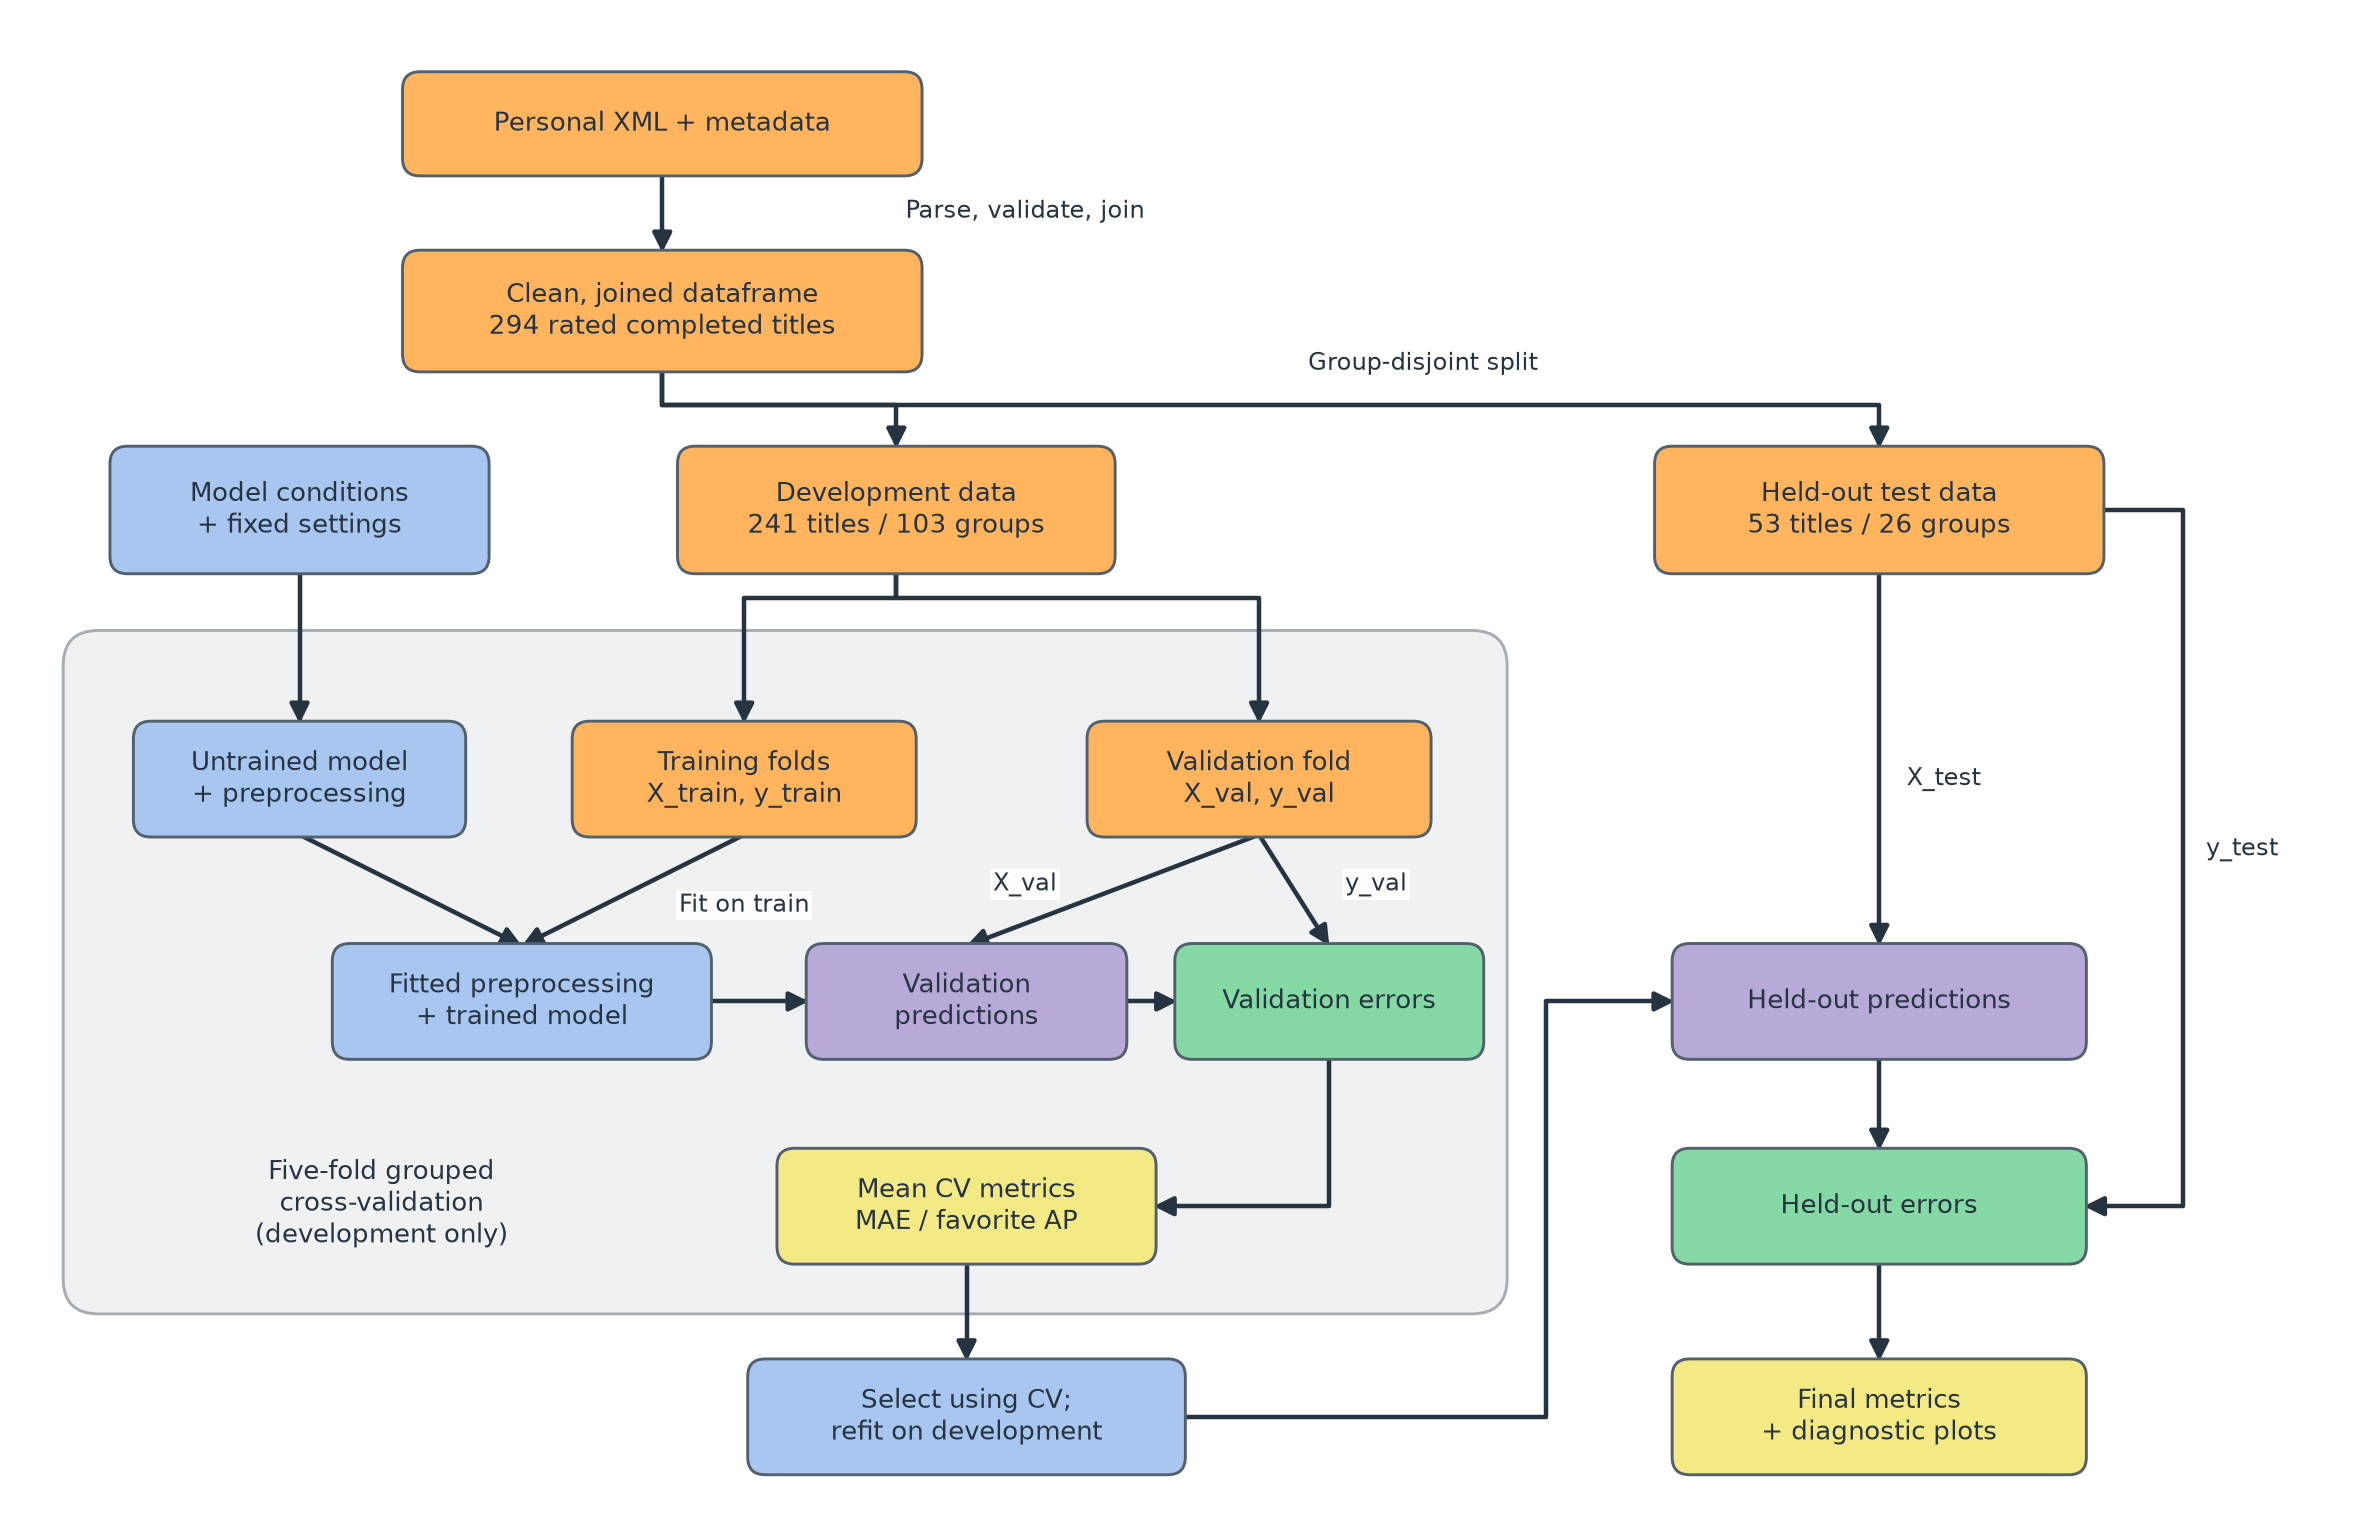

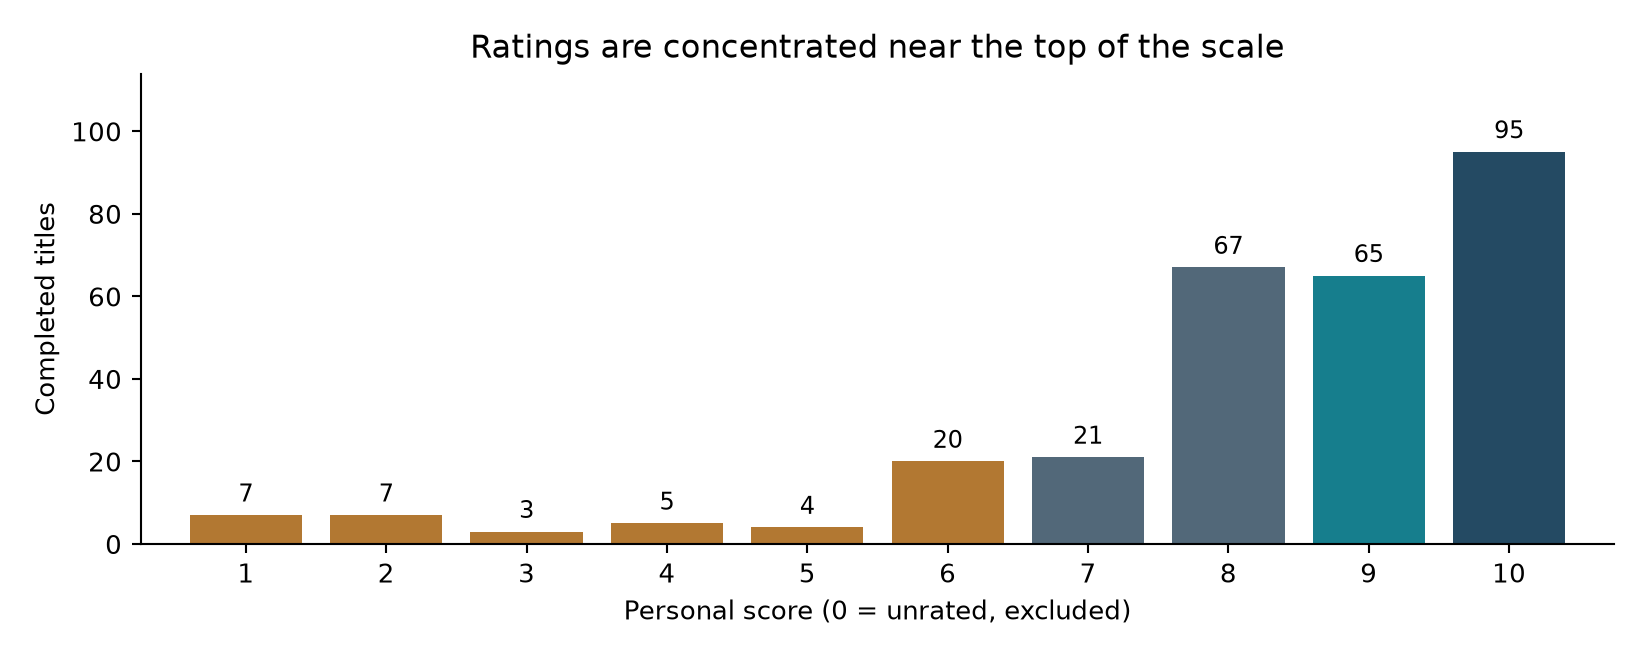

In [4]:
# Execute the fixed, offline protocol in the documented pipeline module.
# It writes the split manifest, fold errors, held-out predictions, diagnostics,
# and figures. Validation metrics choose models before held-out scoring.
display(regressors())
print('Starting the complete offline experiment...')
result = run_experiments()
display(pd.Series(result['audit']))
print('Regression selected by development MAE:', result['audit']['selected_by_cv'])
print('Favorite model selected by development AP:', result['audit']['favorite_selected_by_cv'])
display(Image(filename=str(ROOT/'figures/pipeline.png')))
display(Image(filename=str(ROOT/'figures/rating_distribution.png')))

## 4. Verify group separation and score provenance

These checks verify substantive evaluation invariants. The manifest identifies every primary row and its validation fold. It allows a reader to audit the actual split without rerunning an external API.

In [5]:
# Audit the actual saved split, including every individual validation fold.
# A title ID identifies a row; its relation group is the unit kept disjoint.
# Reindexing the parsed scores by ID verifies that label values survived joins.
manifest = pd.read_csv(ROOT/'results/split_manifest.csv')
dev = manifest[manifest.split=='development']
test = manifest[manifest.split=='test']
assert len(dev)==241 and len(test)==53
assert set(dev.relation_group).isdisjoint(test.relation_group)
for fold in sorted(dev.cv_fold.unique()):
    assert set(dev.loc[dev.cv_fold==fold,'relation_group']).isdisjoint(
        set(dev.loc[dev.cv_fold!=fold,'relation_group']))
assert manifest.score.between(1,10).all()
assert manifest.set_index('anime_id').score.equals(
    raw.set_index('anime_id').score.reindex(manifest.anime_id).rename_axis('anime_id'))
print('Verified: no relation-component overlap; no unrated labels; original XML scores preserved.')
display(dev.groupby('cv_fold').agg(titles=('anime_id','size'), components=('relation_group','nunique')))
display(manifest.groupby('split').score.describe())

Verified: no relation-component overlap; no unrated labels; original XML scores preserved.


,titles,components
cv_fold,,
0,119,21
1,32,21
2,30,21
3,32,20
4,28,20


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
development,241.0,8.141079,2.149809,1.0,8.0,9.0,10.0,10.0
test,53.0,8.415094,2.004168,1.0,8.0,9.0,10.0,10.0


## 5. Final score and favorite performance

The metadata did not establish better overall score prediction. Ridge regression was selected by grouped cross-validation, but its held-out MAE was 1.446, compared with 1.415 for always predicting 9. Favorite classification showed a modest ranking signal: average precision 0.565 versus a 0.415 constant-probability baseline. This is evidence about this archive and split, not a general model of my taste.

The five score conditions were fixed before test evaluation. The model selected by CV remains ridge even though other models lead some test metrics. Fold SD is a variability description, not a confidence interval.

,CV_MAE,CV_SD,Train_MAE,MAE,RMSE,Macro_score_MAE,Lower_MAE,Within_one,Favorite_AP,Spearman
model,,,,,,,,,,
Mean baseline,1.575,0.362,1.559,1.431,2.004,2.346,3.713,0.415,0.415,NaN
Median baseline,1.489,0.360,1.470,1.415,2.070,2.714,4.571,0.830,0.415,NaN
Ridge regression,1.421,0.378,0.975,1.446,1.828,1.907,2.770,0.509,0.478,0.198
Decision tree,1.770,0.316,1.157,1.514,2.183,1.950,2.466,0.472,0.600,0.345
Neural network,1.455,0.284,0.622,1.506,1.825,1.659,2.223,0.415,0.433,0.122


,CV_AP,CV_SD,Test_AP,ROC_AUC,Balanced_accuracy,Brier
model,,,,,,
Prior baseline,0.274,0.067,0.415,0.50,0.500,0.255
Favorite logistic,0.513,0.249,0.565,0.57,0.559,0.251


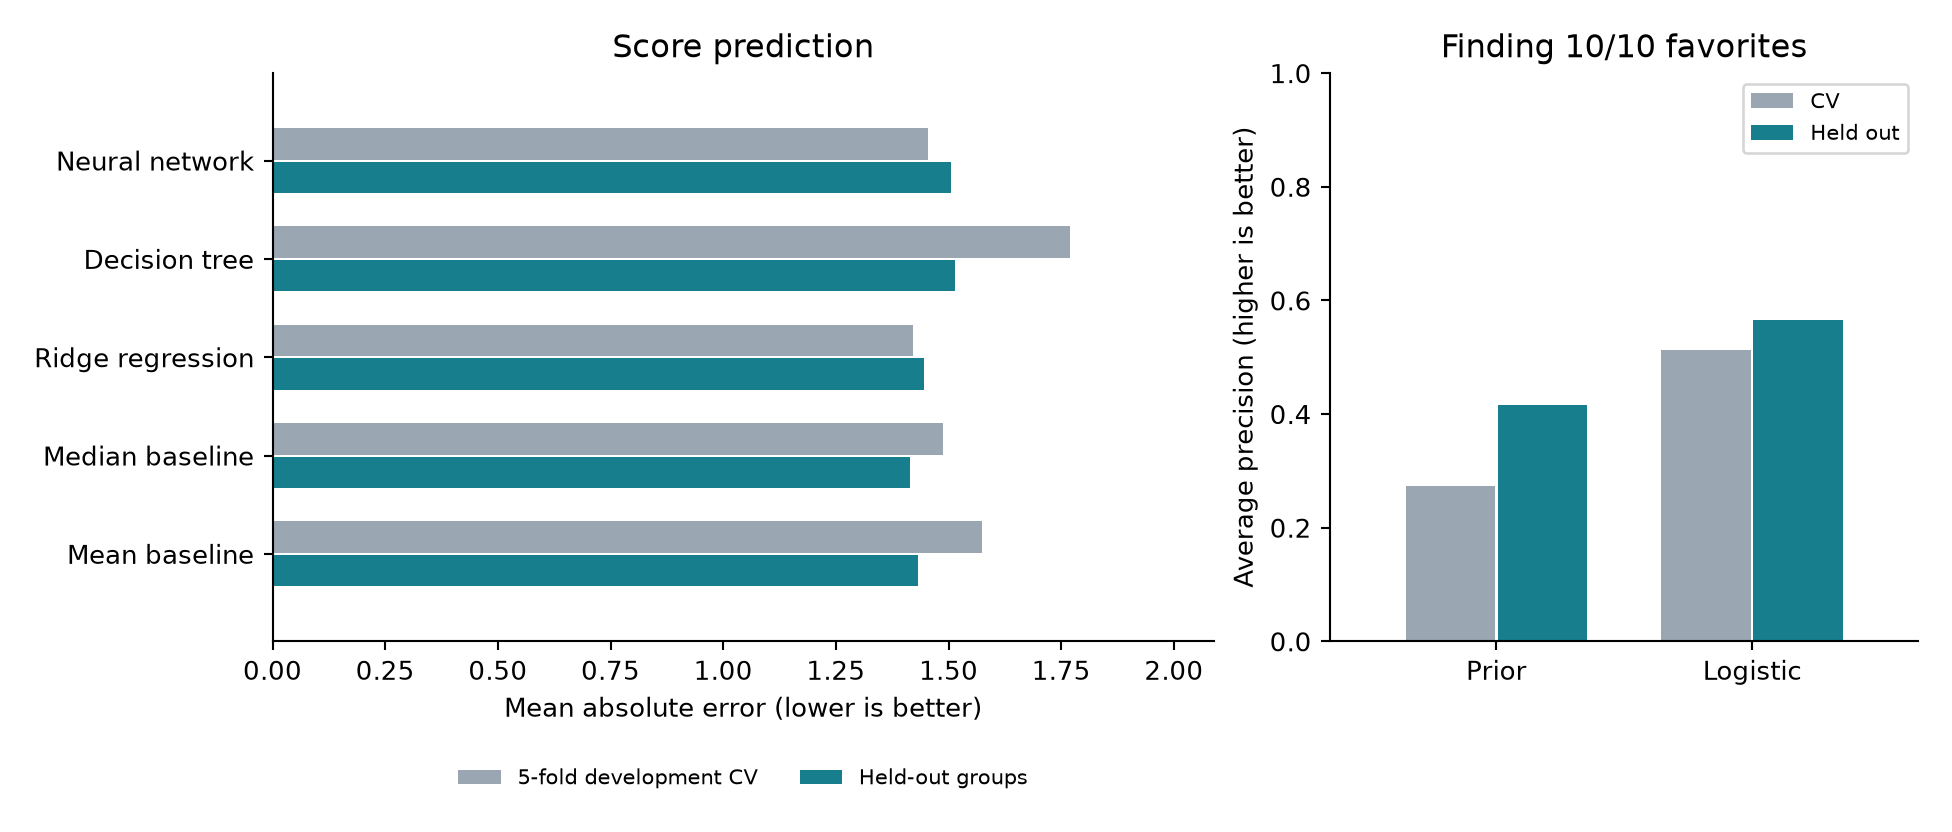

Ridge minus median test MAE: 0.030963765992923283
Paired test-component bootstrap 95% interval: [-0.5946114153670052, 0.3689038393566017]


In [6]:
# Display the precomputed comparison and conditional uncertainty estimate.
# A negative learned-minus-median MAE favors the learned model. The interval
# resamples whole held-out groups and does not refit or select models.
display(result['comparison'].round(3))
display(result['favorites'].round(3))
display(Image(filename=str(ROOT/'figures/model_comparison.png')))
print('Ridge minus median test MAE:', result['audit']['learned_minus_median_test_MAE'])
print('Paired test-component bootstrap 95% interval:', result['audit']['bootstrap_95_interval'])

The interval [-0.595, 0.369] includes zero widely. It resamples 26 held-out components 2,000 times and is conditional on the fitted split. No strong overall MAE improvement is established. Favorite logistic AP is 0.565 versus test prevalence 0.415, but ROC AUC 0.570 and balanced accuracy 0.559 suggest only limited separation. Its development AP varies substantially (SD 0.249). The tree's test AP of 0.600 is reported as an unselected condition; switching to it would use the test set for selection.

## 6. Error analysis and learning behavior

The median baseline gets 83% within one point because high scores dominate. Ridge reduces errors on the seven low-rated test titles and improves RMSE and macro-score MAE, but this is a different tradeoff from minimizing average absolute error. Repeated seasons in an error table are related observations, not independent evidence.

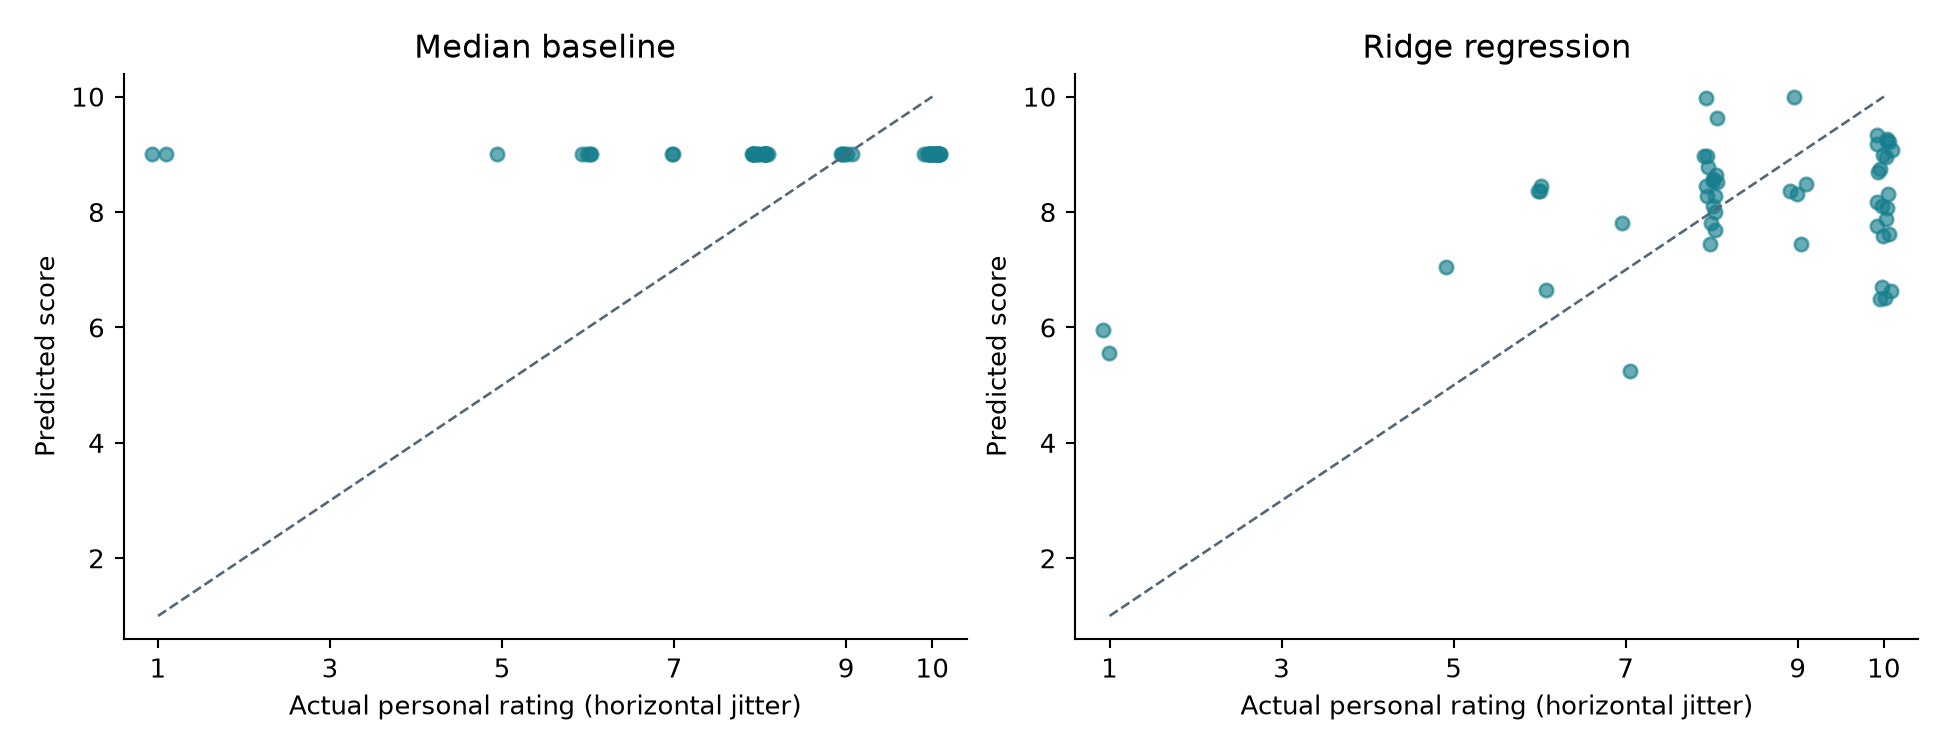

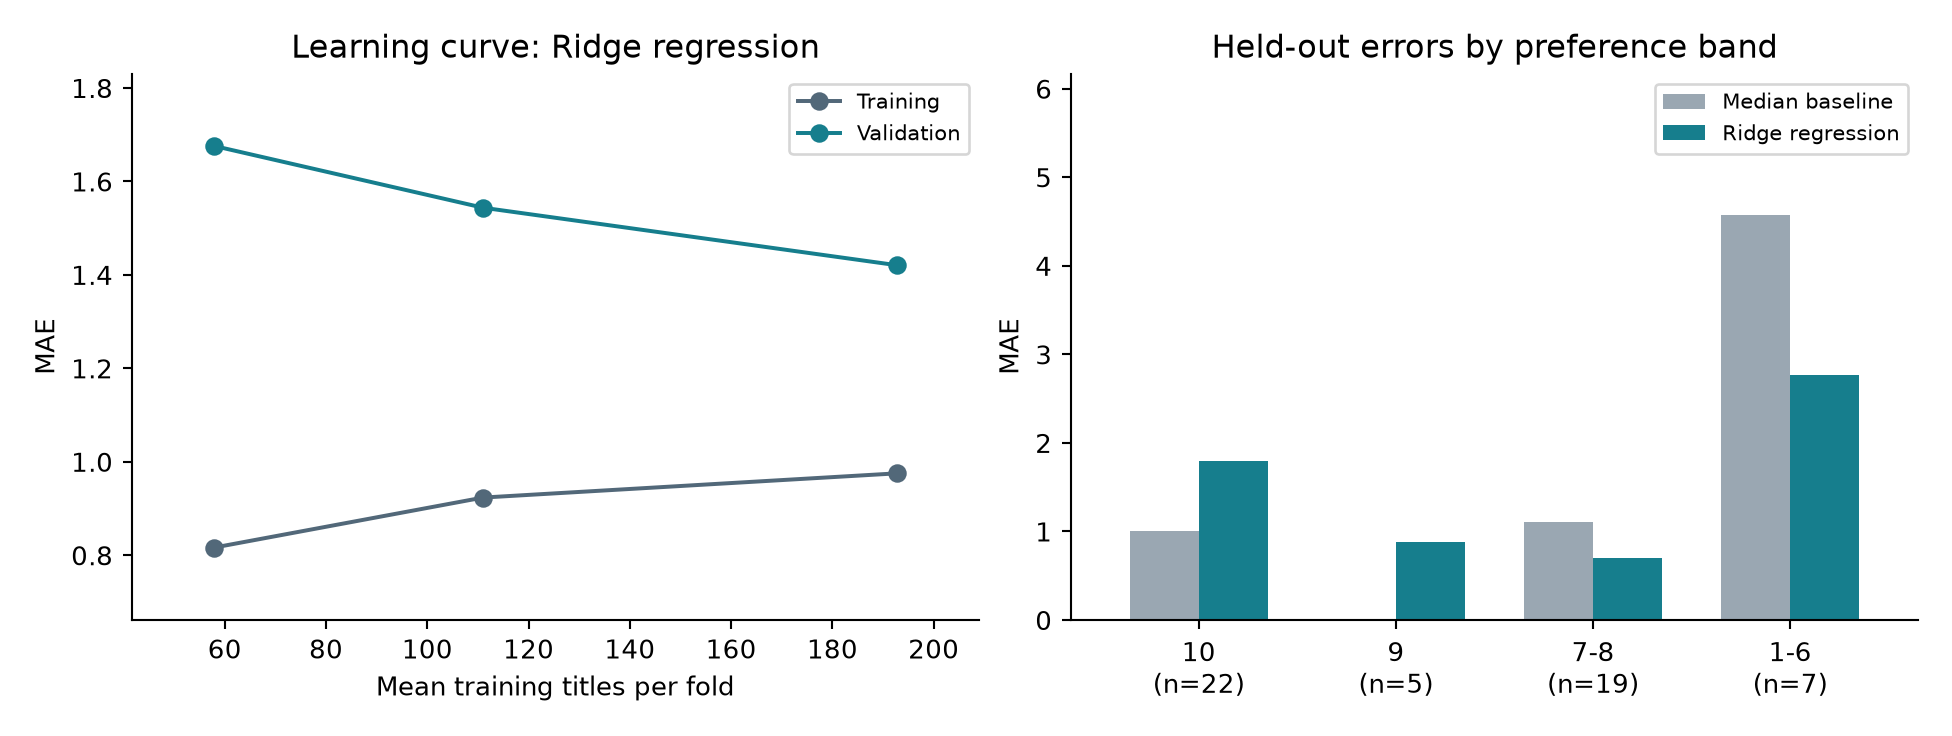

model,Decision tree,Mean baseline,Median baseline,Neural network,Ridge regression
band,,,,,
1-6: lower ratings,2.466,3.713,4.571,2.223,2.770
10: favorites,1.728,1.859,1.000,1.839,1.795
7-8: less impact,0.894,0.246,1.105,0.986,0.704
9: liked a lot,1.598,0.859,0.000,1.011,0.880


,title,score,Ridge regression,absolute_error
5,Kiss x Sis,1,5.949,4.949
8,Kiss x Sis (TV),1,5.561,4.561
22,Kono Subarashii Sekai ni Shukufuku wo!,10,6.486,3.514
25,Kono Subarashii Sekai ni Shukufuku wo! 2,10,6.504,3.496
47,Kono Subarashii Sekai ni Shukufuku wo! 3,10,6.623,3.377
43,Cyberpunk: Edgerunners,10,6.703,3.297
12,Corpse Party: Tortured Souls - Bougyakusareta ...,6,8.447,2.447
39,Re:Zero kara Hajimeru Isekai Seikatsu 2nd Season,10,7.578,2.422
26,Kekkai Sensen & Beyond,10,7.619,2.381
40,Isekai Quartet 2,6,8.372,2.372


,n_train,Train_MAE,Validation_MAE
fraction,,,
0.3,57.8,0.816,1.676
0.6,111.0,0.923,1.544
1.0,192.8,0.975,1.421


In [7]:
# Inspect held-out misses after model selection is complete. Sorting absolute
# errors identifies concrete failures; related seasons remain correlated.
# Grouping learning rows by fraction averages the saved development folds.
display(Image(filename=str(ROOT/'figures/heldout_predictions.png')))
display(Image(filename=str(ROOT/'figures/learning_and_tail_errors.png')))
display(result['bands'].pivot(index='band',columns='model',values='MAE').round(3))
errors=result['predictions'].copy()
errors['absolute_error']=(errors['Ridge regression']-errors.score).abs()
display(errors.sort_values('absolute_error',ascending=False)[['title','score','Ridge regression','absolute_error']].head(10).round(3))
display(result['learning'].groupby('fraction')[['n_train','Train_MAE','Validation_MAE']].mean().round(3))

Kiss x Sis and its TV version were rated 1 but predicted 5.95 and 5.56. Three Kono Subarashii Sekai ni Shukufuku wo! seasons were rated 10 but predicted near 6.5. Broad metadata cannot reliably express why one execution of a trope resonates and another does not. The neural network's larger training/validation gap is consistent with overfitting; more complexity did not improve selected performance.

## 7. Feature ablations and associations

Each ridge ablation is refit in the same development folds; no ablation uses test performance. Coefficients describe conditional penalized associations in the development population. Correlated tags and studio aliases prevent causal interpretation.

In [8]:
# Show development-only feature ablations and fitted ridge associations.
# Coefficients follow transformed feature order and describe conditional
# associations. The population sensitivity has its own grouped CV partition.
display(result['ablations'].round(3))
c=result['coefficients'].sort_values('coefficient')
display(pd.concat([c.head(6),c.tail(6)]).round(3))
display(pd.read_csv(ROOT/'results/population_sensitivity.csv').round(3))

,condition,CV_MAE,CV_SD
0,All features,1.421,0.378
1,No tags,1.627,0.367
2,No studios,1.469,0.392
3,Type + numeric,1.584,0.382


,feature,coefficient
9,tags__harem,-0.984
127,"studios__tnk co., ltd.",-0.842
6,tags__ecchi,-0.735
8,tags__gore,-0.631
107,"studios__production ims co., ltd.",-0.574
26,tags__sci-fi,-0.544
41,tags__vampires,0.486
40,tags__vampire,0.498
17,tags__military,0.535
19,tags__mystery,0.596


,population,model,n,CV_MAE
0,All rated in development groups,Median baseline,253,1.432
1,All rated in development groups,Ridge regression,253,1.426


Removing tags increases development MAE by 0.207, while removing studios increases it by 0.048. Psychological has a positive ridge coefficient (+1.079); harem (-0.984) and ecchi (-0.735) are negative. These patterns summarize this selected archive, not stable universal rules.

Including all rated entries in development components produces a different n=253 population and new folds: ridge MAE 1.426 and median MAE 1.432. This sensitivity check uses a changed population and fold partition. No held-out component is used.

### Exploratory support by tag

The following overlapping tag groups show development support and test error, limited to tags with at least three test titles. These are descriptive diagnostics on the already evaluated test set, not a new selection procedure or reliable proof that frequently watched genres generalize better.

In [9]:
# Summarize overlapping tag groups using the already evaluated predictions.
# ID-based reindexing aligns predictions with each tag subset before subtraction.
# Require three test titles for display, report support counts, and keep this
# diagnostic separate from model selection; small subsets remain uncertain.
joined=primary.merge(manifest[['anime_id','split']],on='anime_id',validate='one_to_one')
pred_by_id=result['predictions'].set_index('anime_id')['Ridge regression']
rows=[]
for tag in sorted(TAGS):
    present=joined.tags.map(lambda value: tag in value.split('|'))
    tr=joined[present & joined.split.eq('development')]
    te=joined[present & joined.split.eq('test')]
    if len(te)>=3:
        rows.append({'tag':tag,'development_n':len(tr),'test_n':len(te),
          'test_MAE':np.abs(te.score.to_numpy()-pred_by_id.reindex(te.anime_id).to_numpy()).mean()})
support=pd.DataFrame(rows).sort_values('development_n',ascending=False)
support.to_csv(ROOT/'results/tag_support_errors.csv',index=False)
display(support.round(3))

,tag,development_n,test_n,test_MAE
4,drama,202,36,1.341
2,comedy,171,41,1.493
0,action,159,34,1.392
6,fantasy,154,37,1.371
24,shounen,119,21,1.303
1,adventure,109,33,1.305
19,school,109,24,1.437
18,romance,109,25,1.455
27,supernatural,108,23,1.201
23,seinen,106,25,1.610


## 8. Discussion

The main conclusion is that a weak score predictor can still reveal why the evaluation problem is difficult. My archive already reflects what I chose to watch, and completing a title is another selection step. The held-out set contains 22 favorites but only seven low-rated titles, so it is easier to appear accurate near the top of the scale than to learn what I dislike. The experiment estimates performance for held-out relation components within this completed archive, not for a random anime from the whole catalog or for future changes in my taste.

Several limitations remain: ordinal ratings are treated as distances for regression; taxonomy synonyms such as vampire/vampires are separate; tags are aggregated and non-curated; connected components may be overly broad; and the snapshot can be older than the export. There are too few examples per many tags to claim reliable genre-specific generalization. The most useful next experiment would collect more independent titles and short personal reasons for liking or disliking them, then test an ordinal or pairwise preference model on a new, untouched evaluation set. For this assignment, the evidence supports a cautious favorite-ranking signal and no demonstrated overall MAE gain.

The selected models were evaluated on one fixed holdout only. With a new dataset, I would test an ordinal or pairwise model and collect short personal reasons for my ratings. This report does not claim the model understands taste or supports reliable full-catalog recommendations.

## Reproducibility and publication

The included source, data snapshot, requirements, figures, results and split manifest reproduce this notebook offline. Code and executed notebook: [cs156-machine-learning / assignment 1](https://github.com/pekkimori/cs156-machine-learning/tree/main/assignment%201). Setup and execution instructions are documented in `scripts/execute_notebook.py`.

AI coding and writing assistance was used. All reported results are from executed code; review the implementation and interpretation before submission.

## References

1. [MyAnimeList XML export](https://myanimelist.net/). Personal export supplied for this assignment; 357 entries. Account identifiers omitted from the shared copy.

2. [Anime Offline Database](https://github.com/manami-project/anime-offline-database). manami-project, release 2026-27, last update July 4, 2026; retrieved October 18, 2026. ODbL 1.0 + DbCL 1.0. Metadata, taxonomy and relation definitions.

3. [Jikan API specification](https://github.com/jikan-me/jikan-rest/blob/master/storage/api-docs/api-docs.json). Original planned metadata source; requests timed out, so no Jikan data enter the experiments.

4. [Scikit-learn: common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html). Train-only preprocessing and pipelines.

5. [Scikit-learn: cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html). Group-based splitting and model selection.

6. [Scikit-learn: Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html). Penalized linear least squares.

7. [Scikit-learn: average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html). Ranking metric and its non-interpolated definition.